# 10 — Sample-based Quantum Diagonalization with `qiskit-addon-sqd`

**Sample-based quantum diagonalization (SQD)** ([IBM Quantum SQD overview](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-addon-sqd)) estimates the ground-state energy of a molecule. It combines a quantum computer
with classical diagonalization:

* The quantum computer *samples* electronic configurations (bitstrings) from a trial state.
* A classical computer projects the Hamiltonian onto the subspace spanned by these configurations and diagonalizes it.
* The energy comes from a classical diagonalization, so it is **variational**. Shot noise does not bias it.
* A self-consistent **configuration recovery** step corrects bitstrings that hardware noise has corrupted.

The [`qiskit-addon-sqd`](https://qiskit.github.io/qiskit-addon-sqd/) package (version 0.14.0 here) provides:

| module | contents |
|---|---|
| [`qiskit_addon_sqd.fermion`](https://qiskit.github.io/qiskit-addon-sqd/apidocs/qiskit_addon_sqd.fermion.html) | the full SQD loop `diagonalize_fermionic_hamiltonian`, and the single projected diagonalization `solve_fermion` / `solve_sci_batch` (built on the selected-CI solver of PySCF) |
| [`qiskit_addon_sqd.configuration_recovery`](https://qiskit.github.io/qiskit-addon-sqd/apidocs/qiskit_addon_sqd.configuration_recovery.html) | `recover_configurations`, which flips bits to restore the correct particle numbers |
| [`qiskit_addon_sqd.subsampling`](https://qiskit.github.io/qiskit-addon-sqd/apidocs/qiskit_addon_sqd.subsampling.html) | `postselect_by_hamming_right_and_left`, `subsample` and `postselect_and_subsample` |
| [`qiskit_addon_sqd.counts`](https://qiskit.github.io/qiskit-addon-sqd/apidocs/qiskit_addon_sqd.counts.html) | helpers that convert counts or a `BitArray` into bitstring matrices, and uniform random samples for baselines |

**Based on**

* SQD guide: [Quickstart](https://qiskit.github.io/qiskit-addon-sqd/guides/quickstart.html). This notebook follows the Quickstart workflow
  (N$_2$, LUCJ ansatz from `ffsim`, `diagonalize_fermionic_hamiltonian`), with a different basis set and active space.
* IBM Quantum tutorial: [Sample-based quantum diagonalization of a chemistry Hamiltonian](https://quantum.cloud.ibm.com/docs/en/tutorials/sample-based-quantum-diagonalization). It treats N$_2$ in the cc-pVDZ basis at a larger size.
* SQD guide: [Bounding the subspace dimension](https://qiskit.github.io/qiskit-addon-sqd/guides/choose_subspace_dimension.html) (Section 10).
* ffsim: [The LUCJ ansatz](https://qiskit-community.github.io/ffsim/explanations/lucj.html) and [Build Qiskit circuits for the LUCJ ansatz](https://qiskit-community.github.io/ffsim/how-to-guides/qiskit-lucj.html) (Sections 3–4).
* PySCF user guide: [MCSCF/CASCI](https://pyscf.org/user/mcscf.html) and [coupled-cluster theory](https://pyscf.org/user/cc.html) (Section 2).

Install line (from `qiskit.def`):

```bash
pip install qiskit-addon-sqd
```

The system is small enough for a laptop or one GPU to simulate.

**Contents**

1. The method: sampling, configuration recovery, projected Hamiltonian
2. The molecule: N$_2$ / 6-31G in a (10e, 10o) active space, with exact CASCI as the reference
3. The LUCJ ansatz from `ffsim`, initialized with CCSD amplitudes
4. Transpiling for a fake IBM backend
5. Sampling with Aer: noiseless and with the noise model of the fake backend
6. One SQD iteration by hand: postselection, subsampling, `solve_fermion`
7. Configuration recovery by hand: the self-consistent loop
8. The full loop with `diagonalize_fermionic_hamiltonian`: energy vs iteration
9. Orbital occupations
10. Subspace size vs accuracy, with a random baseline
11. Summary, notes on the installed version, and references

## 1. The method

**Second-quantized Hamiltonian.** In an active space of $N$ spatial orbitals, the electronic Hamiltonian is

$$
H = \sum_{pq,\sigma} h_{pq}\, a^\dagger_{p\sigma} a_{q\sigma}
  + \frac12 \sum_{pqrs,\sigma\tau} (pq|rs)\, a^\dagger_{p\sigma} a^\dagger_{r\tau} a_{s\tau} a_{q\sigma} + E_\text{core},
$$

with the one-body tensor $h_{pq}$ and the two-body tensor $(pq|rs)$ (chemists' notation). `ffsim` uses the Jordan–Wigner mapping:

* qubits $0,\dots,N-1$ hold the spin-$\alpha$ orbitals;
* qubits $N,\dots,2N-1$ hold the spin-$\beta$ orbitals.

A measured bitstring is therefore a Slater determinant $|x\rangle = |x_\beta\, x_\alpha\rangle$.
In Qiskit bit order, the $\alpha$ half is on the **right**.

**Sampling.** We prepare a trial state $|\psi\rangle$ and measure it in the computational basis. The measured
determinants $x$ follow the distribution $|\langle x|\psi\rangle|^2$. If $|\psi\rangle$ is close to the ground state, its important
determinants appear often.

**Projected Hamiltonian.** Let $\mathcal S$ be a set of determinants and $P_\mathcal S=\sum_{x\in\mathcal S}|x\rangle\langle x|$.
SQD diagonalizes the projected Hamiltonian

$$
H_\mathcal S = P_\mathcal S H P_\mathcal S,\qquad H_\mathcal S |\phi\rangle = E_\mathcal S |\phi\rangle,
\qquad E_\mathcal S \ge E_0 .
$$

* $E_\mathcal S$ is a variational upper bound on the true ground-state energy $E_0$.
* It is computed exactly from the matrix elements $\langle x|H|y\rangle$. Shot noise affects only *which* determinants are in $\mathcal S$, not the energy calculation.
* `qiskit-addon-sqd` takes the unique $\alpha$ strings $\mathcal A$ and $\beta$ strings $\mathcal B$ in the samples
  and uses the **Cartesian product** $\mathcal S=\mathcal A\times\mathcal B$.
* This product subspace is closed under spin flips that preserve $S^2$ (when $\mathcal A=\mathcal B$). The selected-CI code of PySCF handles it efficiently ([`fermion` API](https://qiskit.github.io/qiskit-addon-sqd/apidocs/qiskit_addon_sqd.fermion.html)).

**Configuration recovery** ([`configuration_recovery` API](https://qiskit.github.io/qiskit-addon-sqd/apidocs/qiskit_addon_sqd.configuration_recovery.html)). On noisy hardware, many bitstrings have the wrong number of $\alpha$ or $\beta$ electrons
(the wrong Hamming weight in one half). Discarding them wastes most of the shots. SQD instead *repairs* them:

* It uses the average orbital occupations $n_{p\sigma}$ from the previous iteration.
* It flips bits in the half that has the wrong Hamming weight.
* If there are too many electrons, it flips occupied bits with low occupation. If there are too few, it flips empty bits with high occupation.
* The flips are random. The probability of a flip grows with $|x_{p\sigma}-n_{p\sigma}|$.

**Subsampling and the self-consistent loop.** From the recovered set, we draw `num_batches` batches of `samples_per_batch`
bitstrings each, weighted by their frequency. We diagonalize $H$ in the subspace of each batch, keep the lowest energy, average the
occupations, and repeat:

$$
\{x\}\xrightarrow{\text{recover}(n^{(k)})}\{\tilde x\}\xrightarrow{\text{subsample}}\mathcal S^{(k)}_b
\xrightarrow{\text{diagonalize}}\big(E^{(k)}_b,\ n^{(k+1)}\big)
$$

The first iteration has no occupations yet. It uses only the bitstrings that already have the correct Hamming weights
(postselection). `samples_per_batch` sets the subspace dimension, and therefore the cost and the accuracy ([Bounding the subspace dimension](https://qiskit.github.io/qiskit-addon-sqd/guides/choose_subspace_dimension.html)).

### Setup

We limit the thread pools before importing NumPy and PySCF. Aer uses the GPU if one is available.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("MKL_NUM_THREADS", "2")

import time
import warnings
from functools import partial
from importlib.metadata import version

import numpy as np
import matplotlib.pyplot as plt

import pyscf
from pyscf import cc, mcscf, scf, ao2mo
import ffsim

from qiskit import QuantumCircuit, QuantumRegister
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.primitives import SamplerV2 as AerSampler

from qiskit_addon_sqd.counts import bit_array_to_arrays, generate_bit_array_uniform
from qiskit_addon_sqd.subsampling import postselect_by_hamming_right_and_left, postselect_and_subsample
from qiskit_addon_sqd.configuration_recovery import recover_configurations
from qiskit_addon_sqd.fermion import diagonalize_fermionic_hamiltonian, solve_fermion, solve_sci_batch

warnings.filterwarnings("ignore", category=DeprecationWarning)
for pkg in ["qiskit", "qiskit-aer", "qiskit-ibm-runtime", "qiskit-addon-sqd", "ffsim", "pyscf"]:
    print(f"{pkg:20s} {version(pkg)}")

DEVICE = "GPU" if "GPU" in AerSimulator().available_devices() else "CPU"
print("Aer device:", DEVICE)
T_START = time.perf_counter()

qiskit               2.5.2
qiskit-aer           0.17.2
qiskit-ibm-runtime   0.50.0
qiskit-addon-sqd     0.14.0
ffsim                0.0.80
pyscf                2.14.0
Aer device: GPU


## 2. The molecule and the exact reference

The molecule is **N$_2$ in the 6-31G basis** at a stretched bond length $R=1.4$ Å. At this length, static correlation is noticeable, and CCSD
is less accurate. 6-31G gives 18 molecular orbitals. We freeze the two 1s core orbitals and keep the
**10 lowest valence orbitals with 10 electrons**. This is a (10e, 10o) active space.

* Qubits: $2N = 20$.
* Full CI dimension in the active space: $\binom{10}{5}^2 = 252^2 = 63\,504$ determinants. At this size, **CASCI** in PySCF ([MCSCF user guide](https://pyscf.org/user/mcscf.html))
  gives the exact answer in well under a second. We compare every SQD energy below with it.

`CASCI.get_h1eff()` returns the active-space one-body tensor and $E_\text{core}$ (nuclear repulsion plus frozen-core energy).
`get_h2eff()` returns the two-body tensor. We expand it to the full 4-index form that SQD expects.

In [2]:
R = 1.4  # Angstrom
mol = pyscf.gto.Mole()
mol.build(atom=[["N", (0.0, 0.0, 0.0)], ["N", (R, 0.0, 0.0)]], basis="6-31g", verbose=0)

mf = scf.RHF(mol).run()

norb, n_elec_cas = 10, 10
cas = mcscf.CASCI(mf, norb, n_elec_cas)
cas.verbose = 0
cas.run()
ncore = cas.ncore
nelec = (n_elec_cas // 2, n_elec_cas // 2)          # (n_alpha, n_beta)

hcore, ecore = cas.get_h1eff()                        # one-body tensor and core energy
eri = ao2mo.restore(1, cas.get_h2eff(), norb)         # (pq|rs), shape (norb,)*4

frozen = [i for i in range(mol.nao_nr()) if i < ncore or i >= ncore + norb]
ccsd = cc.CCSD(mf, frozen=frozen)
ccsd.verbose = 0
ccsd.run()

E_HF, E_CCSD, E_EXACT = mf.e_tot, ccsd.e_tot, cas.e_tot
print(f"orbitals: {mol.nao_nr()} total, {ncore} frozen core, {norb} active; nelec = {nelec}")
print(f"RHF    energy: {E_HF:.6f} Ha")
print(f"CCSD   energy: {E_CCSD:.6f} Ha   (error {1e3*(E_CCSD-E_EXACT):6.2f} mHa)")
print(f"CASCI  energy: {E_EXACT:.6f} Ha   <- exact reference in the active space")
print("hcore", hcore.shape, " eri", eri.shape, f" E_core = {ecore:.6f}")

orbitals: 18 total, 2 frozen core, 10 active; nelec = (5, 5)
RHF    energy: -108.699620 Ha
CCSD   energy: -108.897489 Ha   (error  10.06 mHa)
CASCI  energy: -108.907549 Ha   <- exact reference in the active space
hcore (10, 10)  eri (10, 10, 10, 10)  E_core = -80.010508


## 3. The LUCJ ansatz

The trial state is the **local unitary cluster Jastrow** (LUCJ) ansatz ([ffsim: The LUCJ ansatz](https://qiskit-community.github.io/ffsim/explanations/lucj.html)):

$$
|\psi\rangle = \prod_{\mu=1}^{L} e^{K_\mu}\, e^{i J_\mu}\, e^{-K_\mu}\;|\text{HF}\rangle .
$$

* $e^{K_\mu}$ are orbital rotations (networks of Givens rotations).
* $J_\mu$ are diagonal density–density ("Jastrow") terms.
* "Local" means that $J_\mu$ keeps only the interactions that match the hardware connectivity:
  * same-spin pairs $(p, p+1)$: neighbors along the $\alpha$ line and along the $\beta$ line;
  * opposite-spin pairs $(p,p)$ only for $p = 0, 4, 8, \dots$. On a heavy-hex lattice, the two lines connect through an
    ancilla qubit at these positions.

[`ffsim.UCJOpSpinBalanced.from_t_amplitudes`](https://qiskit-community.github.io/ffsim/api/stubs/ffsim.UCJOpSpinBalanced.html) initializes $K_\mu$ and $J_\mu$ from a double factorization of the **CCSD $t_2$
amplitudes**. It adds the $t_1$ amplitudes as a final orbital rotation. We use $L=1$ (`n_reps=1`) and do not optimize the
parameters. In SQD the ansatz only needs to put weight on the right determinants. It does not need to be a good variational state.

In [3]:
pairs_aa = [(p, p + 1) for p in range(norb - 1)]
pairs_ab = [(p, p) for p in range(0, norb, 4)]

ucj_op = ffsim.UCJOpSpinBalanced.from_t_amplitudes(
    t2=ccsd.t2, t1=ccsd.t1, n_reps=1, interaction_pairs=(pairs_aa, pairs_ab)
)

qubits = QuantumRegister(2 * norb, name="q")
circuit = QuantumCircuit(qubits)
circuit.append(ffsim.qiskit.PrepareHartreeFockJW(norb, nelec), qubits)
circuit.append(ffsim.qiskit.UCJOpSpinBalancedJW(ucj_op), qubits)
circuit.measure_all()

# Exact energy of the LUCJ state itself, from ffsim's statevector (for comparison only)
ham = ffsim.MolecularHamiltonian(hcore, eri, constant=ecore)
psi = ffsim.apply_unitary(ffsim.hartree_fock_state(norb, nelec), ucj_op, norb=norb, nelec=nelec)
E_LUCJ = float(np.real(np.vdot(psi, ffsim.linear_operator(ham, norb=norb, nelec=nelec) @ psi)))
print(f"<H> of the (unoptimized) LUCJ state: {E_LUCJ:.6f} Ha  (error {1e3*(E_LUCJ-E_EXACT):.1f} mHa)")
print("weight of the HF determinant in |psi>:", f"{abs(psi[0])**2:.3f}")

<H> of the (unoptimized) LUCJ state: -108.733150 Ha  (error 174.4 mHa)
weight of the HF determinant in |psi>: 0.991


## 4. Transpiling for a fake backend

The target is `FakeSherbrooke`, a snapshot of a 127-qubit Eagle device (heavy-hex lattice, ECR gates) with its calibration data.
`ffsim.qiskit.PRE_INIT` is a pass-manager stage ([ffsim: Merge orbital rotations in Qiskit circuits](https://qiskit-community.github.io/ffsim/how-to-guides/qiskit-merge-orbital-rotations.html)). It decomposes the `ffsim` gates (orbital rotations, diagonal Coulomb
evolutions) into Givens rotations and merges orbital rotations. As the `pre_init` stage, it gives much shallower circuits than
transpilation of the generic decompositions.

In [4]:
backend = FakeSherbrooke()
pm = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=1234)
pm.pre_init = ffsim.qiskit.PRE_INIT

t0 = time.perf_counter()
isa_circuit = pm.run(circuit)
ops = dict(isa_circuit.count_ops())
depth_2q = isa_circuit.depth(lambda inst: inst.operation.num_qubits == 2)
print(f"transpiled in {time.perf_counter()-t0:.1f} s for {backend.name} ({backend.num_qubits} qubits)")
print("gate counts:", ops)
print("two-qubit depth:", depth_2q)

transpiled in 0.1 s for fake_sherbrooke (127 qubits)
gate counts: {'rz': 1279, 'sx': 897, 'ecr': 300, 'x': 20, 'measure': 20, 'barrier': 1}
two-qubit depth: 75


## 5. Sampling with Aer

We run the **same ISA circuit** twice with the Aer `SamplerV2`:

1. **Noiseless**, 100 000 shots. Aer samples from a single final statevector, so this run is cheap.
2. **Noisy**, with a noise model from the calibration data of the fake backend. The model has depolarizing errors on every gate and readout
   errors. We pass `thermal_relaxation=False`. The full model with $T_1/T_2$ relaxation also works, but it is about 2× slower.
   Noisy simulation runs one trajectory *per shot*. The 3 000 shots take about 58 s (about 20 ms per shot).

Timings: one NVIDIA H100 GPU.

Aer removes the idle qubits of the 127-qubit layout, so it simulates only the 20 active qubits.
The sampler returns a `BitArray`. This is the input format of `qiskit-addon-sqd`.

In [5]:
t0 = time.perf_counter()
sampler_ideal = AerSampler(seed=11, options={"backend_options": {"device": DEVICE, "method": "statevector"}})
bits_ideal = sampler_ideal.run([isa_circuit], shots=100_000).result()[0].data.meas
print(f"noiseless: {bits_ideal.num_shots} shots in {time.perf_counter()-t0:.1f} s")

noise_model = NoiseModel.from_backend(backend, thermal_relaxation=False)
noisy_shots = 3_000 if DEVICE == "GPU" else 300   # CPU fallback: one trajectory per shot is slow
t0 = time.perf_counter()
sampler_noisy = AerSampler(
    seed=12,
    options={"backend_options": {"device": DEVICE, "method": "statevector", "noise_model": noise_model}},
)
bits_noisy = sampler_noisy.run([isa_circuit], shots=noisy_shots).result()[0].data.meas
print(f"noisy:     {bits_noisy.num_shots} shots in {time.perf_counter()-t0:.1f} s")

noiseless: 100000 shots in 0.4 s


noisy:     3000 shots in 58.4 s


Next we inspect the samples. For each bitstring, we count the electrons in the $\alpha$ half (right) and in the $\beta$ half (left).
Only bitstrings with $(n_\alpha, n_\beta) = (5,5)$ are determinants of the correct particle-number sector.

noiseless:     50 unique bitstrings, fraction of shots with correct (n_a, n_b): 1.000
noisy    :   1996 unique bitstrings, fraction of shots with correct (n_a, n_b): 0.195


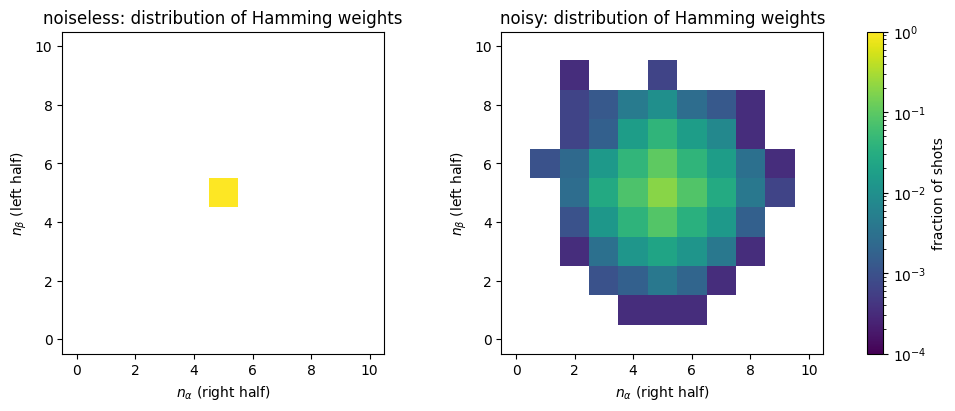

In [6]:
def hamming_stats(bit_array, label):
    mat, probs = bit_array_to_arrays(bit_array)       # unique bitstrings (bool rows) and their frequencies
    n_a = mat[:, norb:].sum(axis=1)                    # right half  = alpha
    n_b = mat[:, :norb].sum(axis=1)                    # left half   = beta
    ok = (n_a == nelec[0]) & (n_b == nelec[1])
    print(f"{label:9s}: {len(mat):6d} unique bitstrings, fraction of shots with correct (n_a, n_b): {probs[ok].sum():.3f}")
    return n_a, n_b, probs

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, (ba, label) in zip(axes, [(bits_ideal, "noiseless"), (bits_noisy, "noisy")]):
    n_a, n_b, probs = hamming_stats(ba, label)
    H, _, _ = np.histogram2d(n_a, n_b, bins=np.arange(-0.5, norb + 1.5), weights=probs)
    im = ax.imshow(H.T, origin="lower", cmap="viridis", norm=plt.matplotlib.colors.LogNorm(vmin=1e-4, vmax=1))
    ax.set_xlabel(r"$n_\alpha$ (right half)"); ax.set_ylabel(r"$n_\beta$ (left half)")
    ax.set_title(f"{label}: distribution of Hamming weights")
fig.colorbar(im, ax=axes, label="fraction of shots")
plt.show()

The noiseless sampler conserves the particle number exactly. The LUCJ state is dominated by the Hartree–Fock determinant, so
it gives only a few dozen distinct bitstrings (50 here). With the hardware-like noise, about **80 % of the shots have the wrong
particle number**. Configuration recovery turns many of these shots back into valid determinants.

## 6. One SQD iteration by hand

Before we use the complete driver function, we run one iteration by hand on the noisy samples, **without** configuration recovery:

1. `postselect_by_hamming_right_and_left`: keep only bitstrings with $n_\alpha=5$ (right) and $n_\beta=5$ (left).
2. `subsample` (here in the combined function `postselect_and_subsample`): draw `num_batches` batches of `samples_per_batch` bitstrings.
3. `solve_fermion`: convert a batch to $\alpha$ and $\beta$ CI strings, build $\mathcal S=\mathcal A\times\mathcal B$, and diagonalize.
   * With `open_shell=False`, the $\alpha$ and $\beta$ strings are merged into one set (spin-symmetric subspace).
   * `spin_sq=0` adds a level shift that favors singlet states.

`solve_fermion` returns the *electronic* energy. We add $E_\text{core}$.

In [7]:
mat_noisy, prob_noisy = bit_array_to_arrays(bits_noisy)
mat_ps, prob_ps = postselect_by_hamming_right_and_left(mat_noisy, prob_noisy, hamming_right=nelec[0], hamming_left=nelec[1])
print(f"postselected: {len(mat_ps)} of {len(mat_noisy)} unique bitstrings survive")

SAMPLES_PER_BATCH, NUM_BATCHES = 100, 3
batches = postselect_and_subsample(
    mat_noisy, prob_noisy, hamming_right=nelec[0], hamming_left=nelec[1],
    samples_per_batch=SAMPLES_PER_BATCH, num_batches=NUM_BATCHES, rand_seed=7,
)
for b, batch in enumerate(batches):
    e, sci_state, occs, s2 = solve_fermion(batch, hcore, eri, open_shell=False, spin_sq=0.0)
    dim = sci_state.amplitudes.size
    print(f"batch {b}: subspace {sci_state.amplitudes.shape} = {dim:6d} dets "
          f"({100*dim/252**2:4.1f}% of FCI), E = {e+ecore:.6f}, error = {1e3*(e+ecore-E_EXACT):6.2f} mHa, <S^2> = {s2:.3f}")

postselected: 217 of 1996 unique bitstrings survive
batch 0: subspace (66, 66) =   4356 dets ( 6.9% of FCI), E = -108.889642, error =  17.91 mHa, <S^2> = 0.011
batch 1: subspace (61, 61) =   3721 dets ( 5.9% of FCI), E = -108.894020, error =  13.53 mHa, <S^2> = 0.011


batch 2: subspace (67, 67) =   4489 dets ( 7.1% of FCI), E = -108.897811, error =   9.74 mHa, <S^2> = 0.008


## 7. Configuration recovery by hand

Now we add configuration recovery and iterate. The initial occupations $n^{(0)}_{p\sigma}$ come from the postselected samples,
weighted by frequency. Bit order: orbital $p$ of spin $\alpha$ is column `2*norb-1-p`, and orbital $p$ of spin $\beta$ is column `norb-1-p`.

Each iteration has three steps:

1. `recover_configurations(mat, probs, (n_alpha_occ, n_beta_occ), 5, 5)` repairs **all** samples, including those with the wrong Hamming weight.
2. `postselect_and_subsample` draws the batches. After recovery, almost every bitstring passes the postselection.
3. `solve_fermion` runs on each batch. We keep the lowest energy and average the occupations over the batches.

In [8]:
def occupations_from_samples(mat, probs):
    occ_a = (probs[:, None] * mat[:, norb:][:, ::-1]).sum(axis=0) / probs.sum()
    occ_b = (probs[:, None] * mat[:, :norb][:, ::-1]).sum(axis=0) / probs.sum()
    return occ_a, occ_b

rng = np.random.default_rng(2024)
occs = occupations_from_samples(mat_ps, prob_ps)
manual_hist = []
for it in range(5):
    mat_rec, prob_rec = recover_configurations(mat_noisy, prob_noisy, occs, nelec[0], nelec[1], rand_seed=rng)
    batches = postselect_and_subsample(
        mat_rec, prob_rec, hamming_right=nelec[0], hamming_left=nelec[1],
        samples_per_batch=SAMPLES_PER_BATCH, num_batches=NUM_BATCHES, rand_seed=rng,
    )
    results = [solve_fermion(b, hcore, eri, open_shell=False, spin_sq=0.0) for b in batches]
    e_best = min(r[0] for r in results) + ecore
    occs = (np.mean([r[2][0] for r in results], axis=0), np.mean([r[2][1] for r in results], axis=0))
    dim = max(r[1].amplitudes.size for r in results)
    manual_hist.append(e_best)
    print(f"iter {it}: {len(mat_rec):5d} unique recovered bitstrings, max subspace {dim:6d}, "
          f"E = {e_best:.6f}, error = {1e3*(e_best-E_EXACT):6.2f} mHa")

iter 0:   798 unique recovered bitstrings, max subspace   4096, E = -108.897132, error =  10.42 mHa


iter 1:   805 unique recovered bitstrings, max subspace   4096, E = -108.897000, error =  10.55 mHa


iter 2:   788 unique recovered bitstrings, max subspace   4761, E = -108.895051, error =  12.50 mHa


iter 3:   803 unique recovered bitstrings, max subspace   4356, E = -108.884760, error =  22.79 mHa


iter 4:   812 unique recovered bitstrings, max subspace   5041, E = -108.895218, error =  12.33 mHa


With configuration recovery, almost all shots are used: about 800 distinct valid determinants, compared with about 200 after
postselection alone. However, the energy **does not decrease monotonically** in this simple loop. Each iteration draws new random
batches of only 100 bitstrings. A draw can include or miss important determinants, so the energy
changes by up to about 12 mHa between iterations. The library driver solves this problem with *carryover*: it always keeps the important
determinants of the previous best state (next section).

## 8. The full SQD loop: `diagonalize_fermionic_hamiltonian`

`diagonalize_fermionic_hamiltonian` runs the complete loop ([Quickstart](https://qiskit.github.io/qiskit-addon-sqd/guides/quickstart.html), [`fermion` API](https://qiskit.github.io/qiskit-addon-sqd/apidocs/qiskit_addon_sqd.fermion.html)):

```python
result = diagonalize_fermionic_hamiltonian(
    hcore, eri, bit_array, samples_per_batch, norb, nelec,
    num_batches=..., max_iterations=..., energy_tol=..., occupancies_tol=...,
    sci_solver=partial(solve_sci_batch, spin_sq=0.0),   # PySCF selected-CI in each subspace
    symmetrize_spin=True,                                # merge alpha and beta strings (closed shell)
    carryover_threshold=1e-4,                            # keep important determinants between iterations
    callback=..., seed=...,
)
```

Compared with the manual loop, it adds two features:

* **carryover**: CI strings with amplitudes above `carryover_threshold` in the best state are added to the subspaces of the next
  iteration. Subsampling therefore never loses good determinants.
* a **convergence test** on both the energy (`energy_tol`) and the occupations (`occupancies_tol`).

It returns an `SCIResult` (`.energy`, `.sci_state`, `.orbital_occupancies`, `.rdm1`, `.rdm2`). A `callback` receives the
list of `SCIResult` objects of each iteration, one per batch. We use it to record the history. As before, `.energy` does not include $E_\text{core}$.

In [9]:
def run_sqd(bit_array, samples_per_batch=100, num_batches=3, max_iterations=10, seed=24):
    history = []

    def callback(results):
        best = min(results, key=lambda r: r.energy)
        history.append({
            "energy": best.energy + ecore,
            "dim": max(r.sci_state.amplitudes.size for r in results),
            "occ": best.orbital_occupancies,
        })

    t0 = time.perf_counter()
    result = diagonalize_fermionic_hamiltonian(
        hcore, eri, bit_array, samples_per_batch=samples_per_batch, norb=norb, nelec=nelec,
        num_batches=num_batches, max_iterations=max_iterations,
        energy_tol=1e-6, occupancies_tol=1e-4,
        sci_solver=partial(solve_sci_batch, spin_sq=0.0),
        symmetrize_spin=True, callback=callback, seed=seed,
    )
    return result, history, time.perf_counter() - t0

runs = {}
for label, ba in [("noiseless", bits_ideal), ("noisy", bits_noisy)]:
    res, hist, dt = run_sqd(ba)
    runs[label] = (res, hist)
    e = res.energy + ecore
    print(f"{label:9s}: {len(hist):2d} iterations in {dt:5.1f} s, final subspace {res.sci_state.amplitudes.shape}, "
          f"E = {e:.6f} Ha, error = {1e3*(e-E_EXACT):7.2f} mHa, <S^2> = {res.sci_state.spin_square():.4f}")

noiseless:  2 iterations in   0.6 s, final subspace (21, 21), E = -108.878877 Ha, error =   28.67 mHa, <S^2> = 0.0039


noisy    : 10 iterations in   6.4 s, final subspace (149, 149), E = -108.907249 Ha, error =    0.30 mHa, <S^2> = 0.0001


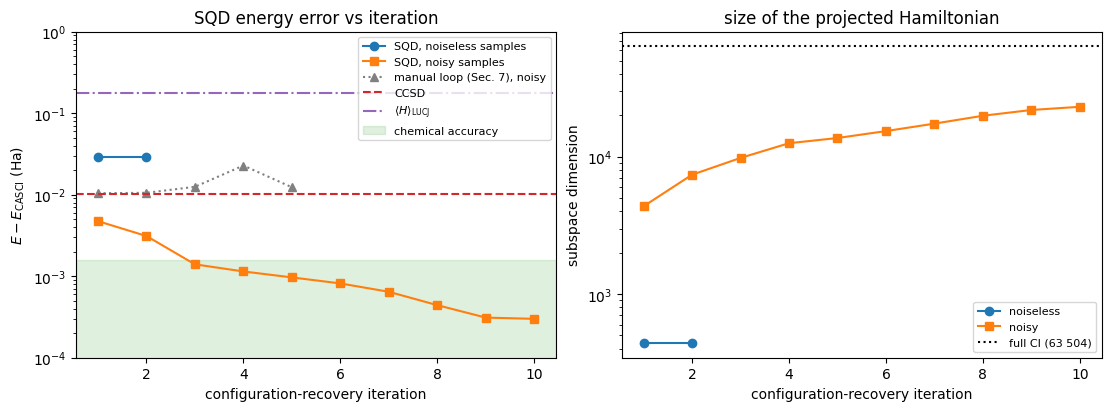

In [10]:
CHEM_ACC = 1.6e-3  # Ha (1 kcal/mol)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ax = axes[0]
for label, (res, hist), mk in [("noiseless", runs["noiseless"], "o"), ("noisy", runs["noisy"], "s")]:
    it = np.arange(1, len(hist) + 1)
    ax.semilogy(it, [h["energy"] - E_EXACT for h in hist], marker=mk, label=f"SQD, {label} samples")
ax.semilogy(np.arange(1, len(manual_hist) + 1), np.array(manual_hist) - E_EXACT, "^:", color="gray",
            label="manual loop (Sec. 7), noisy")
ax.axhline(E_CCSD - E_EXACT, color="C3", ls="--", label="CCSD")
ax.axhline(E_LUCJ - E_EXACT, color="C4", ls="-.", label=r"$\langle H\rangle_\mathrm{LUCJ}$")
ax.axhspan(1e-6, CHEM_ACC, color="C2", alpha=0.15, label="chemical accuracy")
ax.set_ylim(1e-4, 1); ax.set_xlabel("configuration-recovery iteration"); ax.set_ylabel(r"$E - E_\mathrm{CASCI}$ (Ha)")
ax.set_title("SQD energy error vs iteration"); ax.legend(fontsize=8)

ax = axes[1]
for label, (res, hist), mk in [("noiseless", runs["noiseless"], "o"), ("noisy", runs["noisy"], "s")]:
    ax.plot(np.arange(1, len(hist) + 1), [h["dim"] for h in hist], marker=mk, label=label)
ax.axhline(252**2, color="k", ls=":", label="full CI (63 504)")
ax.set_yscale("log"); ax.set_xlabel("configuration-recovery iteration"); ax.set_ylabel("subspace dimension")
ax.set_title("size of the projected Hamiltonian"); ax.legend(fontsize=8)
plt.show()

**Interpretation of the plots**

* The **noisy** run converges steadily. In each iteration the occupations improve, so recovery produces better determinants. Carryover
  keeps the important ones, the subspace grows, and the energy approaches the exact CASCI value. The final error (0.30 mHa) is well below the CCSD error (10.06 mHa).
* The **noiseless** run stops after two iterations, at a *higher* energy. The unoptimized LUCJ state puts almost all of its
  weight on a few determinants. Even 100 000 shots give only a few dozen distinct $\alpha$/$\beta$ strings, so the
  product subspace stays small. SQD cannot add a determinant that was never sampled.
* At this small size, hardware noise *broadens* the sampled distribution. Configuration recovery maps the noisy
  shots onto determinants close to the important ones. For large molecules the effect is the opposite. The Hilbert space is
  very large, random noise almost never produces a relevant determinant, and the quality of the sampled state decides the result.
  Section 10 checks this point with a uniform random baseline.

## 9. Orbital occupations

The orbital occupations $n_{p\sigma}=\langle a^\dagger_{p\sigma}a_{p\sigma}\rangle$ control configuration recovery. We compare the
spin-summed SQD occupations with the exact CASCI values. We also show how the occupations of the noisy run change over the iterations.

In the stretched molecule, most of the correlation is in the $\pi$ system:

* the degenerate $\pi$ bonding pair (orbitals 3, 4) has about 1.85 electrons per orbital;
* the $\pi^*$ pair (orbitals 5, 6) has about 0.15 electrons per orbital.

Hartree–Fock would give exactly 2 and 0.

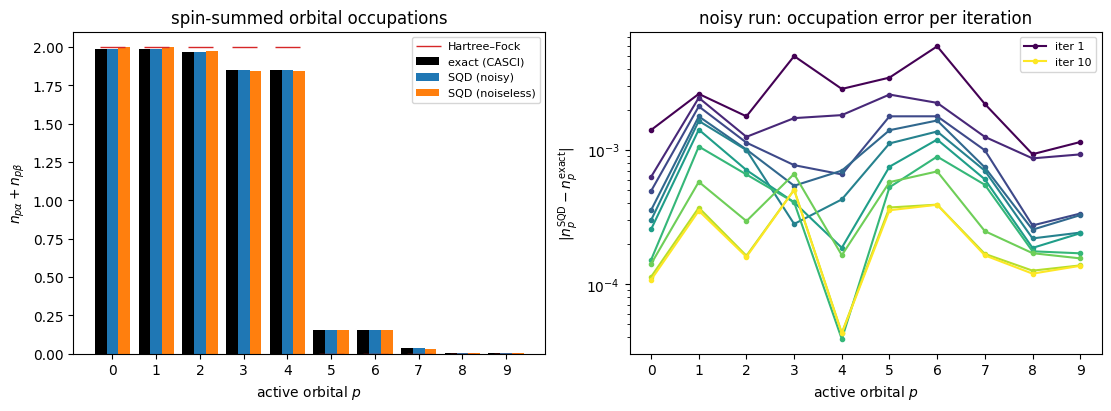

exact occupations: [1.988 1.984 1.968 1.85  1.85  0.155 0.155 0.04  0.005 0.005]
max |n_SQD - n_exact|  noisy: 0.0005  noiseless: 0.01394


In [11]:
dm1a, dm1b = cas.fcisolver.make_rdm1s(cas.ci, norb, nelec)
occ_exact = np.diag(dm1a) + np.diag(dm1b)
occ_hf = np.array([2.0] * nelec[0] + [0.0] * (norb - nelec[0]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ax = axes[0]
x = np.arange(norb); w = 0.27
ax.bar(x - w, occ_exact, w, label="exact (CASCI)", color="k")
for k, label in enumerate(["noisy", "noiseless"]):
    oa, ob = runs[label][0].orbital_occupancies
    ax.bar(x + k * w, oa + ob, w, label=f"SQD ({label})")
ax.plot(x, occ_hf, "_", ms=18, color="C3", label="Hartree–Fock")
ax.set_xticks(x); ax.set_xlabel("active orbital $p$"); ax.set_ylabel(r"$n_{p\alpha}+n_{p\beta}$")
ax.set_title("spin-summed orbital occupations"); ax.legend(fontsize=8)

ax = axes[1]
hist = runs["noisy"][1]
for k, h in enumerate(hist):
    oa, ob = h["occ"]
    ax.plot(x, np.abs(oa + ob - occ_exact), marker=".", color=plt.cm.viridis(k / max(1, len(hist) - 1)),
            label=f"iter {k+1}" if k in (0, len(hist) - 1) else None)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xlabel("active orbital $p$")
ax.set_ylabel(r"$|n_p^\mathrm{SQD}-n_p^\mathrm{exact}|$"); ax.set_title("noisy run: occupation error per iteration")
ax.legend(fontsize=8)
plt.show()
print("exact occupations:", occ_exact.round(3))
print("max |n_SQD - n_exact|  noisy:", np.abs(sum(runs['noisy'][0].orbital_occupancies) - occ_exact).max().round(5),
      " noiseless:", np.abs(sum(runs['noiseless'][0].orbital_occupancies) - occ_exact).max().round(5))

## 10. Subspace size vs accuracy, with a random baseline

`samples_per_batch` is the main parameter ([Bounding the subspace dimension](https://qiskit.github.io/qiskit-addon-sqd/guides/choose_subspace_dimension.html)). More samples give a larger subspace, a lower energy and a higher cost. The cost of the
diagonalization grows with the subspace dimension.

We scan `samples_per_batch` for the noisy samples. As a baseline, we use **uniformly random bitstrings**
(`generate_bit_array_uniform`) with the same number of shots. They go through the same recovery loop.

This comparison is a recommended sanity check for SQD. Each spin has only 252 possible strings, so
a few hundred random samples already cover a large part of the space. At this size even random input works. A quantum sampler
has a real advantage only when the important determinants are a very small fraction of the space.

scan done in 35.5 s
  spb | noisy dim err (mHa) | uniform dim err (mHa)
   25 |      3969     8.137 |       14641    10.241
   50 |      8836     1.637 |       26896     0.933
  100 |     15376     0.815 |       42025     0.016
  200 |     27556     0.191 |       52441     0.001


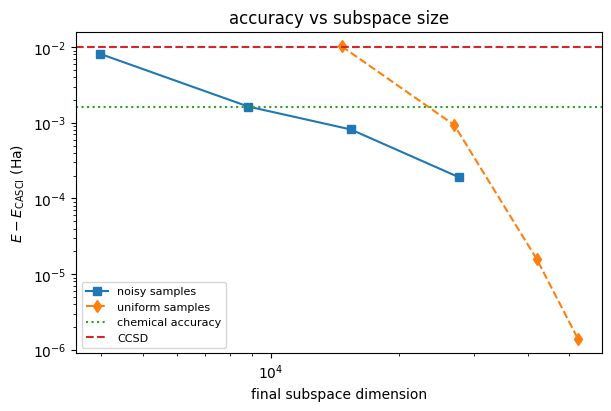

total notebook compute time: 107 s


In [12]:
bits_uniform = generate_bit_array_uniform(bits_noisy.num_shots, 2 * norb, rand_seed=5)
scan = {"noisy": [], "uniform": []}
spb_values = [25, 50, 100, 200]
t0 = time.perf_counter()
for spb in spb_values:
    for label, ba in [("noisy", bits_noisy), ("uniform", bits_uniform)]:
        res, hist, _ = run_sqd(ba, samples_per_batch=spb, max_iterations=6)
        scan[label].append((res.sci_state.amplitudes.size, res.energy + ecore - E_EXACT))
print(f"scan done in {time.perf_counter()-t0:.1f} s")
print(f"{'spb':>5s} | {'noisy dim':>9s} {'err (mHa)':>9s} | {'uniform dim':>11s} {'err (mHa)':>9s}")
for spb, (dn, en), (du, eu) in zip(spb_values, scan["noisy"], scan["uniform"]):
    print(f"{spb:5d} | {dn:9d} {1e3*en:9.3f} | {du:11d} {1e3*eu:9.3f}")

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
for label, mk in [("noisy", "s-"), ("uniform", "d--")]:
    d, e = zip(*scan[label])
    ax.loglog(d, e, mk, label=f"{label} samples")
ax.axhline(CHEM_ACC, color="C2", ls=":", label="chemical accuracy")
ax.axhline(E_CCSD - E_EXACT, color="C3", ls="--", label="CCSD")
ax.set_xlabel("final subspace dimension"); ax.set_ylabel(r"$E - E_\mathrm{CASCI}$ (Ha)")
ax.set_title("accuracy vs subspace size"); ax.legend(fontsize=8)
plt.show()
print(f"total notebook compute time: {time.perf_counter()-T_START:.0f} s")

**Interpretation of the scan**

* For the same `samples_per_batch`, uniform samples give *larger* subspaces than noisy samples. Random bitstrings are spread
  over all strings, while the noisy LUCJ samples stay concentrated near Hartree–Fock. Larger subspaces give lower energies.
* **At equal subspace dimension, the noisy quantum samples are more accurate.** In the plot, the noisy curve lies below the uniform
  curve, by a factor of about 5 to 10. Even with hardware-like noise, the samples contain information about which
  determinants are important.
* Both sample sets reach chemical accuracy here only because the subspaces cover about 25–80 % of the full CI space. For chemically
  interesting sizes ($10^{15}$ determinants and more), such coverage is impossible, and the quality of the sampled distribution decides the result.

## 11. Summary, notes on the installed version, and references

**Workflow summary**

1. PySCF builds the active-space integrals (`CASCI.get_h1eff` / `get_h2eff`), the CCSD amplitudes and the exact CASCI reference.
2. `ffsim.UCJOpSpinBalanced.from_t_amplitudes` creates the LUCJ ansatz with `interaction_pairs` that fit a heavy-hex lattice.
   `PrepareHartreeFockJW` + `UCJOpSpinBalancedJW` give the circuit. `ffsim.qiskit.PRE_INIT` keeps it shallow after transpilation.
3. Sampling: any `SamplerV2` that returns a `BitArray`. Here we used Aer, noiseless and with a `FakeSherbrooke` noise model.
4. `diagonalize_fermionic_hamiltonian(hcore, eri, bit_array, samples_per_batch, norb, nelec, ...)` runs configuration recovery,
   subsampling, projected diagonalization (`solve_sci_batch`) and carryover until convergence. The building blocks
   (`recover_configurations`, `postselect_and_subsample`, `solve_fermion`) can be used in custom loops.

**Notes on the installed version (v0.14.0)**

* **Bit order.** The $\alpha$ string is the *right* half of a Qiskit bitstring, and the $\beta$ string is the left half. In each half,
  orbital 0 is the rightmost bit. `recover_configurations` takes the occupations as a tuple `(occ_alpha, occ_beta)`. A 1D array is deprecated.
* **Energies do not include the core energy.** `solve_fermion`, `solve_sci` and `SCIResult.energy` return the electronic active-space
  energy. Workaround: add `E_core` (`ecore` from `get_h1eff`).
* **Input format.** The packed `uint8` array `BitArray.array` has the wrong width and fails with "The length of the bitstrings must be even".
  Workaround: pass a `BitArray` or a boolean matrix.
* `carryover_threshold` and a custom `policy` cannot be used together (`ValueError`). Workaround: set the threshold on `StandardPolicy`.
* **Few distinct determinants.** An unoptimized, weakly correlated LUCJ state samples very few distinct determinants. Noiseless SQD can then be *worse* than
  CCSD. More shots do not help. Workaround: a better or deeper ansatz (larger `n_reps`, parameter optimization).
* **Small active spaces favor SQD.** At (10e, 10o), a few hundred random samples also recover the energy (Section 10). Compare
  with a random baseline before you attribute accuracy to the quantum sampler.
* **Simulation cost.** Noisy Aer simulation runs one trajectory per shot (about 20 ms per shot for this 20-qubit circuit on one H100 GPU;
  about 2× more with thermal relaxation). `batched_shots_gpu` and shot branching did not make this circuit faster.
  For larger studies, use the noiseless sampler or `ffsim` sampling with a synthetic noise model.
* **Reproducibility.** Noisy GPU sampling in Aer is not bit-for-bit reproducible, even with `seed=` set on the sampler.
  The final SQD error of the noisy run varies between runs (from about 0.3 to 0.6 mHa). The
  qualitative conclusions do not change.
* The orbital-optimization helper `optimize_orbitals` is deprecated in 0.14. See the SQD guide [Optimize orbitals](https://qiskit.github.io/qiskit-addon-sqd/guides/optimize_orbitals.html).
* For larger problems, [`TrimPolicy`](https://qiskit.github.io/qiskit-addon-sqd/guides/trim_sqd.html) screens and merges subspaces (SQD guide: *Leverage trim SQD for improved configuration selection*).

**References**

1. SQD guide: *Quickstart*. https://qiskit.github.io/qiskit-addon-sqd/guides/quickstart.html
2. SQD guide: *Bounding the subspace dimension*. https://qiskit.github.io/qiskit-addon-sqd/guides/choose_subspace_dimension.html
3. SQD guide: *Optimize orbitals*. https://qiskit.github.io/qiskit-addon-sqd/guides/optimize_orbitals.html
4. SQD guide: *Leverage trim SQD for improved configuration selection*. https://qiskit.github.io/qiskit-addon-sqd/guides/trim_sqd.html
5. API: `qiskit_addon_sqd.fermion`. https://qiskit.github.io/qiskit-addon-sqd/apidocs/qiskit_addon_sqd.fermion.html
6. API: `qiskit_addon_sqd.configuration_recovery`. https://qiskit.github.io/qiskit-addon-sqd/apidocs/qiskit_addon_sqd.configuration_recovery.html
7. API: `qiskit_addon_sqd.subsampling`. https://qiskit.github.io/qiskit-addon-sqd/apidocs/qiskit_addon_sqd.subsampling.html
8. API: `qiskit_addon_sqd.counts`. https://qiskit.github.io/qiskit-addon-sqd/apidocs/qiskit_addon_sqd.counts.html
9. IBM Quantum tutorial: *Sample-based quantum diagonalization of a chemistry Hamiltonian*. https://quantum.cloud.ibm.com/docs/en/tutorials/sample-based-quantum-diagonalization
10. IBM Quantum documentation: *Sample-based quantum diagonalization (SQD)*. https://quantum.cloud.ibm.com/docs/en/addons/qiskit-addon-sqd
11. ffsim explanation: *The local unitary cluster Jastrow (LUCJ) ansatz*. https://qiskit-community.github.io/ffsim/explanations/lucj.html
12. ffsim how-to: *Build Qiskit circuits for the LUCJ ansatz*. https://qiskit-community.github.io/ffsim/how-to-guides/qiskit-lucj.html
13. ffsim how-to: *Merge orbital rotations in Qiskit circuits*. https://qiskit-community.github.io/ffsim/how-to-guides/qiskit-merge-orbital-rotations.html
14. ffsim API: `UCJOpSpinBalanced`. https://qiskit-community.github.io/ffsim/api/stubs/ffsim.UCJOpSpinBalanced.html
15. PySCF user guide: *Multi-configuration self-consistent field (MCSCF)*. https://pyscf.org/user/mcscf.html
16. PySCF user guide: *Coupled-cluster theory*. https://pyscf.org/user/cc.html